In [1]:
import numpy as np
from keras.models import Sequential
from keras.layers import Dense
import matplotlib.pyplot as plt

In [2]:
x_real = np.array([[1,2],[2,4],[3,6],[4,8],[5,10],[6,12],[7,14],[8,16],[9,18],[10,20]],dtype=float)
x_real = x_real / 10.0
y_real = np.array([[1]] * 10,dtype=float)

In [3]:
np.shape(y_real)

(10, 1)

In [4]:
discriminator = Sequential()
discriminator.add(Dense(32,activation="relu",input_dim=2))
discriminator.add(Dense(16,activation="relu"))
discriminator.add(Dense(1,activation="sigmoid"))
discriminator.compile(loss="binary_crossentropy",optimizer="adam",metrics=["accuracy"])
discriminator.trainable = False

In [5]:
generator = Sequential()
generator.add(Dense(32,activation="relu",input_dim=2))
generator.add(Dense(16,activation="relu"))
generator.add(Dense(2,activation="linear"))

In [6]:
GAN = Sequential()
GAN.add(generator)
GAN.add(discriminator)
GAN.compile(loss="binary_crossentropy",optimizer="adam")

In [7]:
np.shape(x_real)

(10, 2)

Epoch 0


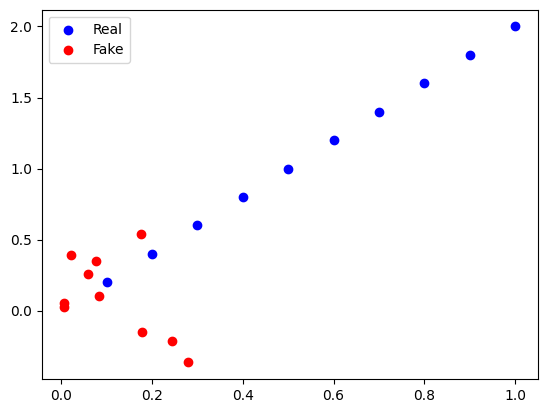

Epoch 100


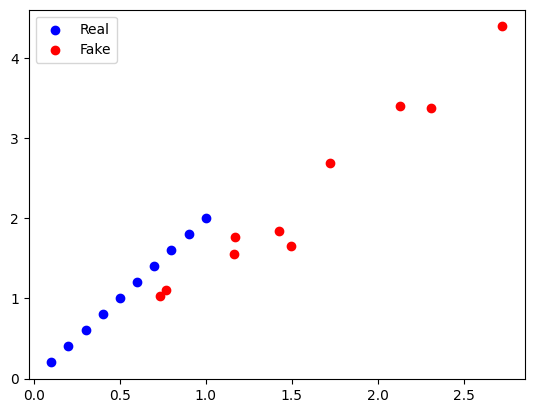

Epoch 200


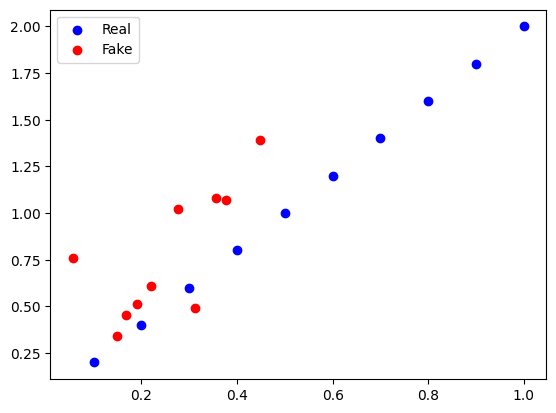

Epoch 300


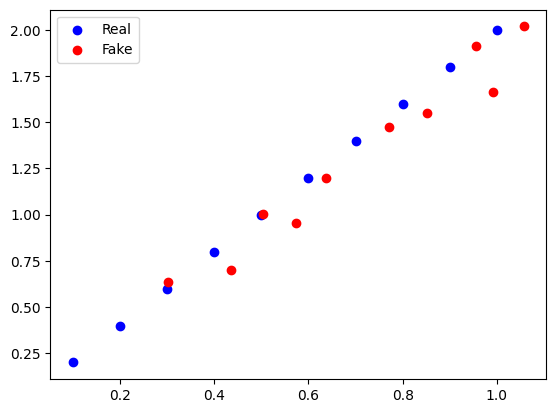

Epoch 400


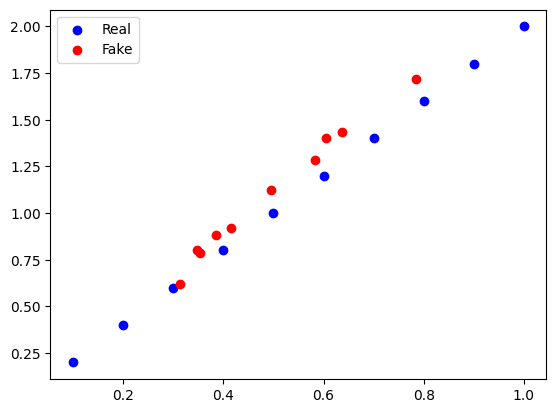

Epoch 500


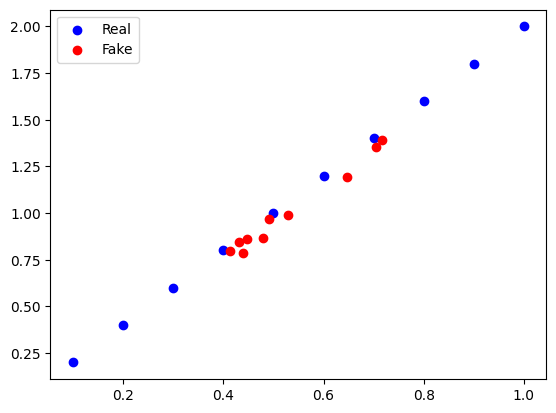

KeyboardInterrupt: 

In [8]:
epochs = 5000
batch = 10

for epoch in range(epochs):
    noise = np.random.normal(0,1,(batch,2))
    generate = generator.predict(noise,verbose=0)

    real_labels = np.ones((batch,1))
    fake_labels = np.zeros((batch,1))

    discriminator.trainable = True
    real_data = discriminator.train_on_batch(x_real,real_labels)
    fake_data = discriminator.train_on_batch(generate,fake_labels)
    discriminator.trainable = False

    noise = np.random.normal(0,1,(batch,2))
    ones = np.ones((batch,1))
    GAN.train_on_batch(noise,ones)

    if epoch %100 == 0:
        print(f"Epoch {epoch}")
        noise = np.random.normal(0,1,(batch,2))
        fake_data = generator.predict(noise,verbose=0)
        plt.scatter(x_real[:,0],x_real[:,1],label="Real",color="blue")
        plt.scatter(fake_data[:,0],fake_data[:,1],label="Fake",color="red")
        plt.legend()
        plt.show()